In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from keras.layers import Input, Dense, Dropout, BatchNormalization
from keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix, roc_curve
from keras.models import Sequential

In [87]:
df = pd.read_csv('/kaggle/input/datasets/samvelgalstyan/loantrain/train.csv')

In [88]:
df

,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
0,0,29367.99,0.084,736,2528.42,13.67,Female,Single,High School,Self-employed,Other,C3,1.0
1,1,22108.02,0.166,636,4593.10,12.92,Male,Married,Master's,Employed,Debt consolidation,D3,0.0
2,2,49566.20,0.097,694,17005.15,9.76,Male,Single,High School,Employed,Debt consolidation,C5,1.0
3,3,46858.25,0.065,533,4682.48,16.10,Female,Single,High School,Employed,Debt consolidation,F1,1.0
4,4,25496.70,0.053,665,12184.43,10.21,Male,Married,High School,Employed,Other,D1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
593989,593989,23004.26,0.152,703,20958.37,10.92,Female,Single,High School,Employed,Business,C3,1.0
593990,593990,35289.43,0.105,559,3257.24,14.62,Male,Single,Bachelor's,Employed,Debt consolidation,F5,1.0
593991,593991,47112.64,0.072,675,929.27,14.13,Female,Married,Bachelor's,Employed,Debt consolidation,C1,1.0
593992,593992,76748.44,0.067,740,16290.40,9.87,Male,Single,Bachelor's,Employed,Debt consolidation,B2,1.0


In [89]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 593994 entries, 0 to 593993
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    593994 non-null  int64  
 1   annual_income         593994 non-null  float64
 2   debt_to_income_ratio  593994 non-null  float64
 3   credit_score          593994 non-null  int64  
 4   loan_amount           593994 non-null  float64
 5   interest_rate         593994 non-null  float64
 6   gender                593994 non-null  object 
 7   marital_status        593994 non-null  object 
 8   education_level       593994 non-null  object 
 9   employment_status     593994 non-null  object 
 10  loan_purpose          593994 non-null  object 
 11  grade_subgrade        593994 non-null  object 
 12  loan_paid_back        593994 non-null  float64
dtypes: float64(5), int64(2), object(6)
memory usage: 58.9+ MB


In [90]:
df = df.drop('id',axis=1)

In [91]:
X = df.drop('loan_paid_back',axis=1)
y = df['loan_paid_back']

In [92]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [93]:
num_cols = X_train.select_dtypes('int','float').columns
str_cols = X_train.select_dtypes('object').columns
num_cols_binary = [i for i in num_cols if X_train[i].max() > 1]
num_cols_numeric = [j for j in num_cols if X_train[j].max() <= 1]

In [94]:
preprocessor = ColumnTransformer([
   ( 'cat', OneHotEncoder(drop='first', handle_unknown='ignore'), str_cols),
    ('num_scale', StandardScaler(), num_cols_numeric),
    ('num_unscale', 'passthrough', num_cols_binary)
])

In [95]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [108]:
model = Sequential()

model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(128, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.2))
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

In [109]:
model.compile(optimizer=Adam(learning_rate=0.00001), loss='binary_crossentropy', metrics = ['auc'])

In [110]:
model.fit(X_train,y_train, validation_split=0.15, epochs=15)

Epoch 1/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - auc: 0.6979 - loss: 0.4817 - val_auc: 0.8365 - val_loss: 0.3400
Epoch 2/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - auc: 0.8396 - loss: 0.3276 - val_auc: 0.8598 - val_loss: 0.3041
Epoch 3/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 33s 3ms/step - auc: 0.8490 - loss: 0.3149 - val_auc: 0.8608 - val_loss: 0.3085
Epoch 4/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - auc: 0.8522 - loss: 0.3115 - val_auc: 0.8634 - val_loss: 0.3007
Epoch 5/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 33s 3ms/step - auc: 0.8536 - loss: 0.3097 - val_auc: 0.8637 - val_loss: 0.3028
Epoch 6/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - auc: 0.8548 - loss: 0.3087 - val_auc: 0.8620 - val_loss: 0.3317
Epoch 7/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 32s 3ms/step - auc: 0.8553 - loss: 0.3080 - val_auc: 0.8641 - val_loss: 0.2999
Epoch 8/15
12623/12623 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - auc: 0.8561 - loss: 0.3068 - val_auc: 0.8646 - val_loss: 0.3008
Epoch 9/15
12623

In [114]:
y_pred = model.predict(X_test).ravel()

3713/3713 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step


In [115]:
fpr, tpr, threshold = roc_curve(y_test, y_pred)

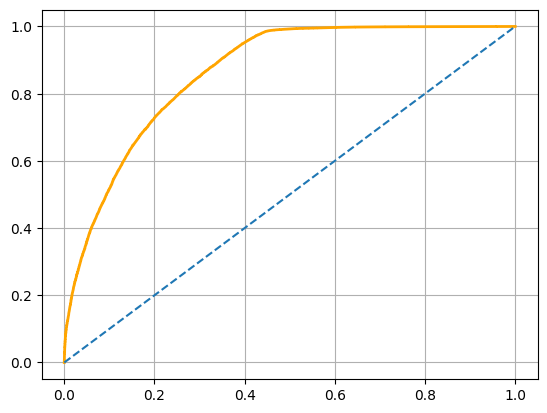

In [123]:
plt.plot(fpr, tpr, color='orange', linewidth=2)
plt.plot([0,1],[0,1], linestyle='dashed')
plt.grid(True)

In [124]:
youden = np.argmax(tpr - fpr)
best_threshold = threshold[youden]

In [126]:
y_pred = (y_pred > best_threshold).astype(int)

In [128]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

         0.0       0.67      0.63      0.65     23997
         1.0       0.91      0.92      0.92     94802

    accuracy                           0.86    118799
   macro avg       0.79      0.78      0.78    118799
weighted avg       0.86      0.86      0.86    118799



In [129]:
confusion_matrix(y_test,y_pred)

array([[15183,  8814],
       [ 7377, 87425]])

<Axes: >

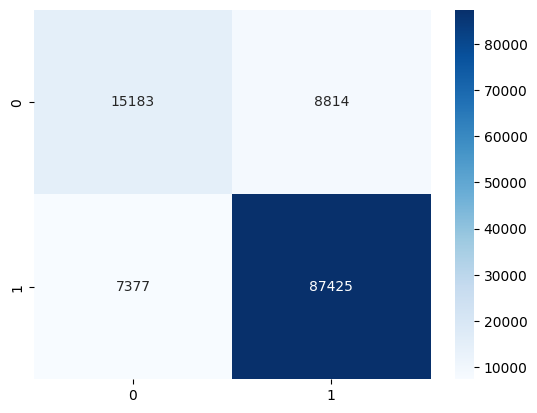

In [131]:
sns.heatmap(confusion_matrix(y_test,y_pred), cmap='Blues', annot=True, fmt='d')